In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("SAT-GPA.csv")

In [4]:
df.head()

,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SAT     84 non-null     int64  
 1   GPA     84 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 1.4 KB


In [6]:
df.describe()

,SAT,GPA
count,84.000000,84.000000
mean,1845.273810,3.330238
std,104.530661,0.271617
min,1634.000000,2.400000
25%,1772.000000,3.190000
50%,1846.000000,3.380000
75%,1934.000000,3.502500
max,2050.000000,3.810000


In [7]:
df.corr()

,SAT,GPA
SAT,1.000000,0.637184
GPA,0.637184,1.000000


<Axes: >

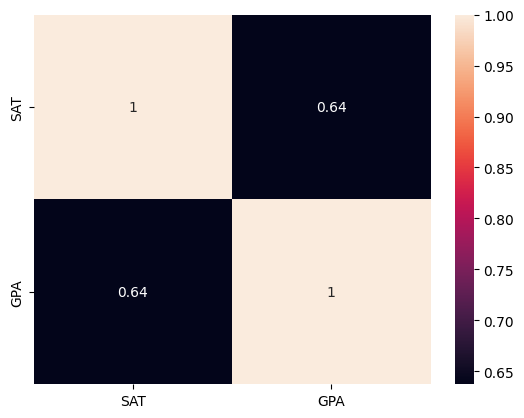

In [8]:
sns.heatmap(df.corr(), annot=True)

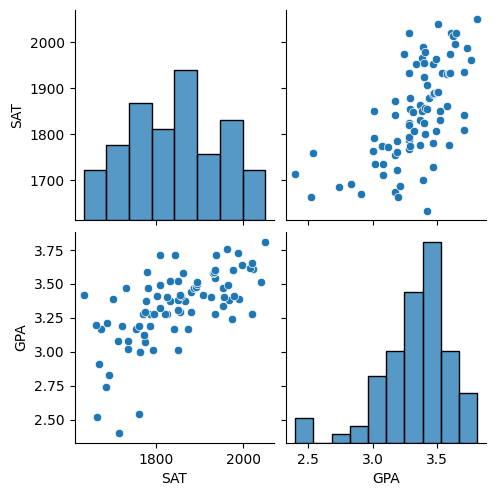

In [9]:
sns.pairplot(df)

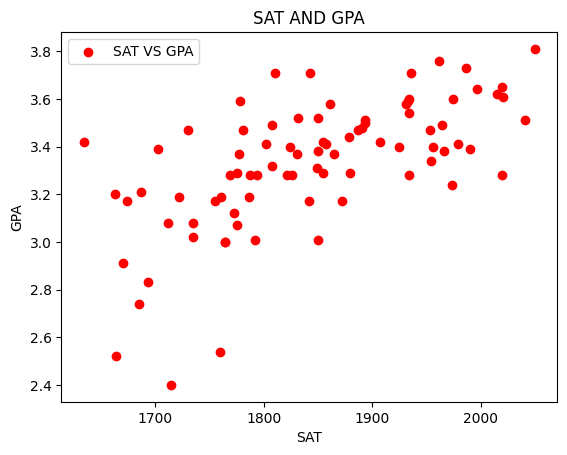

In [19]:
plt.scatter(df['SAT'],df['GPA'],color="red",label="SAT VS GPA")
plt.title("SAT AND GPA")
plt.xlabel("SAT")
plt.ylabel("GPA")
plt.legend()


In [10]:
X=df.drop('GPA', axis=1)
y=df['GPA']
X

,SAT
0,1714
1,1664
2,1760
3,1685
4,1693
...,...
79,1936
80,1810
81,1987
82,1962


In [56]:
from sklearn.preprocessing import PolynomialFeatures

# create an object of Polynomial features
polynomial_terms = PolynomialFeatures(degree=3)

# add the polynomial terms in X
# this will add two new features => X^0 and X^2
preprocessed_X = polynomial_terms.fit_transform(X)
preprocessed_X

array([[1.00000000e+00, 1.71400000e+03, 2.93779600e+06, 5.03538234e+09],
       [1.00000000e+00, 1.66400000e+03, 2.76889600e+06, 4.60744294e+09],
       [1.00000000e+00, 1.76000000e+03, 3.09760000e+06, 5.45177600e+09],
       [1.00000000e+00, 1.68500000e+03, 2.83922500e+06, 4.78409412e+09],
       [1.00000000e+00, 1.69300000e+03, 2.86624900e+06, 4.85255956e+09],
       [1.00000000e+00, 1.67000000e+03, 2.78890000e+06, 4.65746300e+09],
       [1.00000000e+00, 1.76400000e+03, 3.11169600e+06, 5.48903174e+09],
       [1.00000000e+00, 1.76400000e+03, 3.11169600e+06, 5.48903174e+09],
       [1.00000000e+00, 1.79200000e+03, 3.21126400e+06, 5.75458509e+09],
       [1.00000000e+00, 1.85000000e+03, 3.42250000e+06, 6.33162500e+09],
       [1.00000000e+00, 1.73500000e+03, 3.01022500e+06, 5.22274038e+09],
       [1.00000000e+00, 1.77500000e+03, 3.15062500e+06, 5.59235938e+09],
       [1.00000000e+00, 1.73500000e+03, 3.01022500e+06, 5.22274038e+09],
       [1.00000000e+00, 1.71200000e+03, 2.93094400e

In [57]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    preprocessed_X,y,train_size=0.7, random_state=42)

In [58]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)


LinearRegression()

In [59]:
y_pred=model.predict(X_test)

In [60]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print(f"mean absolute error = {mae:.2f}")

mean absolute error = 0.16


In [61]:
from sklearn.metrics import mean_absolute_percentage_error

# calculate mean absolute percentage error
mape = mean_absolute_percentage_error(y_test, y_pred)
print(f"mean absolute percentage error = {mape:.2f}")

mean absolute percentage error = 0.05


In [62]:
from sklearn.metrics import mean_squared_error

# calculage mean squared error 
mse = mean_squared_error(y_test, y_pred)
print(f"mean squared error = {mse:.2f}")

mean squared error = 0.05


In [63]:
from sklearn.metrics import mean_squared_log_error

# calculate mean squared log error
msle = mean_squared_log_error(y_test, y_pred)
print(f"mean squared log error = {msle:.2f}")

mean squared log error = 0.00


In [64]:
from sklearn.metrics import root_mean_squared_error

# calculate root mean squared error
rmse = root_mean_squared_error(y_test, y_pred)
print(f"root mean squared error: {rmse:.2f}")

root mean squared error: 0.21


In [65]:
from sklearn.metrics import root_mean_squared_log_error

# calculate root mean squared log error
rmsle = root_mean_squared_log_error(y_test, y_pred)
print(f"root mean squared log error = {rmsle:.2f}")


root mean squared log error = 0.05


In [66]:
from sklearn.metrics import r2_score

# calculate R-squared value 
r2 = r2_score(y_test, y_pred)
print(f"R-squared value = {r2:.2f}")

R-squared value = 0.42


In [68]:
n = y_test.size    # no of records
p = 3             # no of features
adjusted_r2 = 1 - ((1 - r2) * ((n - 1) / (n - p - 1)))

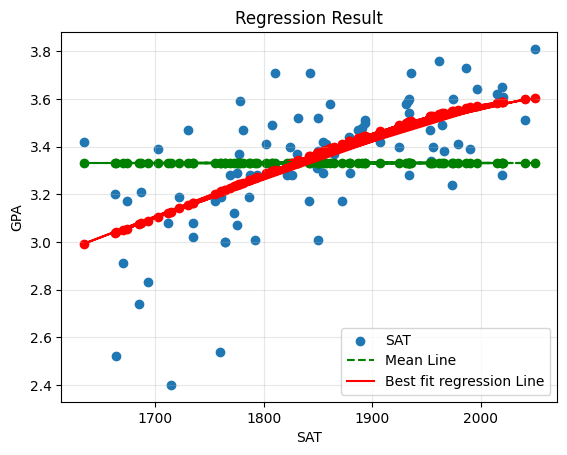

In [67]:
y_pred = model.predict(preprocessed_X)

# plot the whole dataset
plt.scatter(df['SAT'], y, label="SAT")

# plot a mean line
mean_values = np.ones(y.size) * y.mean()
plt.scatter(df['SAT'], mean_values, color="green")
plt.plot(df['SAT'], mean_values, color="green", linestyle="--", label="Mean Line")

# plot a best fit curvilinear regression line
plt.scatter(df['SAT'], y_pred, color="red")
plt.plot(df['SAT'], y_pred, color="red", label="Best fit regression Line")


plt.title("Regression Result")
plt.xlabel("SAT")
plt.ylabel("GPA")
plt.legend()
plt.grid(visible=True, alpha=0.3)

In [69]:
model.intercept_

35.55953794804049

In [70]:
model.coef_

array([ 0.00000000e+00, -5.85898837e-02,  3.41977840e-05, -6.44963422e-09])